# 🚀 Practice Day 10

**📅 Date:** 2026-11-12  
**📁 Category:** Phase 3 · NumPy + 통계 응용 (Round 1/5)

---
# 🎯 Today's Goal
*What am I trying to solve today?*

- Measure the relationship between two variables with a correlation coefficient (상관계수로 두 변수 간 관계 측정)
- Detect outliers systematically with the IQR method, using pure NumPy (순수 NumPy로 IQR 방식 이상치 탐지)
- Compare mean vs. median to see how outliers pull the average (평균과 중앙값을 비교해서 이상치가 평균을 어떻게 끌어올리는지 확인)

---
# 📂 Dataset

**Dataset Name:** Customer Satisfaction Survey + Purchase Data (고객 만족도 설문 + 매출 데이터)

**Source:** Synthetically generated for practice, fixed random seed (연습용으로 코드에서 직접 생성, seed 고정)

**Description:** 280 customers with a satisfaction survey score (1-10), total purchase amount (USD), and visit count. Purchase amount is built to correlate with satisfaction score, and 6 customers are deliberately injected as purchase-amount outliers ("whale" spenders) so the IQR method has something real to detect.
(고객 280명 — 만족도 설문 점수(1~10), 총 매출액(USD), 방문 횟수 포함. 매출액은 만족도와 상관관계를 갖도록 설계했고, IQR 방법이 실제로 잡아낼 수 있도록 매출액 이상치("과다 지출" 고객) 6명을 의도적으로 포함했습니다.)

## Dataset Preview

In [17]:
# Dataset Preview
import numpy as np
import pandas as pd

np.random.seed(42)

n_customers = 280

# satisfaction_score: 1-10, roughly bell-shaped around 7 (typical survey pattern)
satisfaction_score = np.clip(np.round(np.random.normal(7, 1.8, n_customers)), 1, 10).astype(int)

# purchase_amount is driven by satisfaction_score plus noise (positive correlation)
base_amount = 20 + satisfaction_score * 15  # USD
purchase_amount = np.round(base_amount + np.random.normal(0, 25, n_customers), 2)  # nearest cent
purchase_amount = np.clip(purchase_amount, 5, None)

# visit_count loosely tracks satisfaction too
visit_count = np.clip(np.round(satisfaction_score * 0.8 + np.random.normal(0, 2, n_customers)), 1, None).astype(int)

# inject 6 deliberate outliers in purchase_amount ("whale" spenders)
outlier_idx = np.random.choice(n_customers, size=6, replace=False)
purchase_amount[outlier_idx] = purchase_amount[outlier_idx] + np.random.randint(300, 600, size=6)

df = pd.DataFrame({
    'customer_id': [f'CUST-{i+1:04d}' for i in range(n_customers)],
    'satisfaction_score': satisfaction_score,
    'purchase_amount': purchase_amount,
    'visit_count': visit_count,
})

df.head()

,customer_id,satisfaction_score,purchase_amount,visit_count
0,CUST-0001,8,142.84,7
1,CUST-0002,7,141.55,10
2,CUST-0003,8,179.65,8
3,CUST-0004,10,139.05,7
4,CUST-0005,7,178.33,8


## Dataset Information

In [18]:
# Dataset Information
print(df.shape)
df.info()
df.describe()

(280, 4)
<class 'pandas.DataFrame'>
RangeIndex: 280 entries, 0 to 279
Data columns (total 4 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   customer_id         280 non-null    str    
 1   satisfaction_score  280 non-null    int64  
 2   purchase_amount     280 non-null    float64
 3   visit_count         280 non-null    int64  
dtypes: float64(1), int64(2), str(1)
memory usage: 8.9 KB


,satisfaction_score,purchase_amount,visit_count
count,280.000000,280.000000,280.000000
mean,6.914286,131.670857,5.600000
std,1.720572,67.633684,2.437167
min,1.000000,44.320000,1.000000
25%,6.000000,99.847500,4.000000
50%,7.000000,122.115000,5.500000
75%,8.000000,148.765000,7.000000
max,10.000000,582.740000,12.000000


---
# ❓ Business Questions

1. What is the correlation coefficient between satisfaction_score and purchase_amount? (만족도와 매출액의 상관계수는?)
2. Using the IQR method, which customers have outlier purchase amounts? (IQR 방법으로 봤을 때 매출액이 이상치인 고객은?)
3. What are the mean, median, and standard deviation of purchase_amount? (매출액의 평균, 중앙값, 표준편차는?)
4. How does purchase_amount relate to satisfaction_score visually? (만족도와 매출액의 관계를 시각적으로 보면 어떤 모습인가?)
5. Where do the outlier purchase amounts fall relative to the rest of the distribution? (이상치들이 전체 분포에서 어디에 위치하는가?)

---
# 🛠 Skills Used
- [x] Python — f-strings, boolean masks  
 (f-string 출력, 불리언 마스크)  
- [x] NumPy — `np.corrcoef`, `np.percentile`, `np.mean`, `np.median`, `np.std`  
 (상관계수, 사분위수, 평균, 중앙값, 표준편차)  
- [x] Pandas — column selection, boolean filter  
 (컬럼 선택, 조건 필터)  
- [ ] SQL  
- [x] Matplotlib — `plt.figure`, `plt.title`, axis formatter  
 (그림 크기, 제목, 축 형식)  
- [x] Other: Seaborn — `scatterplot`, `boxplot`  
 (산점도, 박스플롯)  

---
# 🔍 Data Cleaning Check

Things I checked:
- [x] Missing Values — **0** in every column  
 (모든 컬럼에서 결측치 **0**)  
- [x] Duplicate Rows — **0**  
 (중복 행 **0**)  
- [x] Wrong Data Types — `purchase_amount` is `float64`, the others are `int64` and `str`  
 (`purchase_amount`는 `float64`, 나머지는 `int64`와 `str`)  
- [ ] Rename Columns — not needed  
- [ ] Drop Columns — not needed  


In [19]:
# Data Cleaning Check — inspect only. Fixes are in Q1–Q3.
# (확인만. 수정은 Q1~Q3)

print("Missing values")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nDtypes")
print(df.dtypes)

print("\nColumn names")
print(df.columns.tolist())

obj_cols = df.select_dtypes(include=["object", "string"]).columns
print("\nText columns — unique counts")
print(df[obj_cols].nunique())


Missing values
customer_id           0
satisfaction_score    0
purchase_amount       0
visit_count           0
dtype: int64

Duplicate rows: 0

Dtypes
customer_id               str
satisfaction_score      int64
purchase_amount       float64
visit_count             int64
dtype: object

Column names
['customer_id', 'satisfaction_score', 'purchase_amount', 'visit_count']

Text columns — unique counts
customer_id    280
dtype: int64


---
# 📊 Analysis

## Question 1

**Question:** What is the correlation coefficient between satisfaction_score and purchase_amount? (만족도와 매출액의 상관계수는?)

**Result:** The correlation coefficient is **0.44**.  
(상관계수는 **0.44**)

**Insight:** It is positive, so higher satisfaction goes with higher purchase amounts. It is moderate, not close to 1.  
(양수라서 만족도가 높을수록 구매 금액도 높은 경향. 1에 가깝지는 않은 중간 정도)

In [20]:
# Question 1: Correlation coefficient between satisfaction_score and purchase_amount
# Tip: np.corrcoef(x, y) returns a 2x2 matrix - the correlation is at [0, 1]
# (순수 NumPy 함수 사용)

corr_coef = np.corrcoef(df['satisfaction_score'], df['purchase_amount'])[0, 1]
print(f"Correlation coefficient: {corr_coef:.2f}")

Correlation coefficient: 0.44


## Question 2

**Question:** Using the IQR method, which customers have outlier purchase amounts? (IQR 방법으로 봤을 때 매출액이 이상치인 고객은?)

**Result:** The bounds are **$26.47** and **$222.14**, and **6** customers are above the upper bound: CUST-0010 (**$515.43**), CUST-0043 (**$479.54**), CUST-0119 (**$531.14**), CUST-0129 (**$513.01**), CUST-0213 (**$501.93**), CUST-0232 (**$582.74**).  
(경계는 **$26.47**과 **$222.14**이고, 상한 위의 고객은 **6**명: CUST-0010 **$515.43**, CUST-0043 **$479.54**, CUST-0119 **$531.14**, CUST-0129 **$513.01**, CUST-0213 **$501.93**, CUST-0232 **$582.74**)

**Insight:** All **6** outliers are high spenders and none is below the lower bound. The smallest one, **$479.54**, is **$257.40** above the upper bound.  
(이상치 **6**명은 모두 높은 쪽이고 하한 아래는 없음. 가장 작은 **$479.54**도 상한보다 **$257.40** 높음)

In [21]:
# Question 2: IQR method - Q1 = 25th percentile, Q3 = 75th percentile, IQR = Q3 - Q1
# Outliers are values below (Q1 - 1.5*IQR) or above (Q3 + 1.5*IQR)
# Tip: use np.percentile()
# (순수 NumPy 함수 사용)

iqr = np.percentile(df['purchase_amount'], 75) - np.percentile(df['purchase_amount'], 25)
lower_bound = np.percentile(df['purchase_amount'], 25) - 1.5 * iqr
upper_bound = np.percentile(df['purchase_amount'], 75) + 1.5 * iqr
outlier_mask = (df['purchase_amount'] < lower_bound) | (df['purchase_amount'] > upper_bound)
outlier_customers = df[outlier_mask]['customer_id']
print(f"Outlier customers: {outlier_customers.tolist()}")
print(f"Lower bound: {lower_bound:.2f}, Upper bound: {upper_bound:.2f}")
print(f"Outlier count: {outlier_mask.sum()}")
print(df[outlier_mask][['customer_id', 'purchase_amount']])


Outlier customers: ['CUST-0010', 'CUST-0043', 'CUST-0119', 'CUST-0129', 'CUST-0213', 'CUST-0232']
Lower bound: 26.47, Upper bound: 222.14
Outlier count: 6
    customer_id  purchase_amount
9     CUST-0010           515.43
42    CUST-0043           479.54
118   CUST-0119           531.14
128   CUST-0129           513.01
212   CUST-0213           501.93
231   CUST-0232           582.74


## Question 3

**Question:** What are the mean, median, and standard deviation of purchase_amount? (매출액의 평균, 중앙값, 표준편차는?)

**Result:** The mean is **$131.67**, the median is **$122.12**, and the standard deviation is **$67.51**.  
(평균 **$131.67**, 중앙값 **$122.12**, 표준편차 **$67.51**)

**Insight:** The mean is **$9.55** above the median, because the outliers pull the mean up. `np.std` uses ddof=0, so it is slightly lower than the `describe()` value.  
(평균이 중앙값보다 **$9.55** 높은데, 이상치가 평균을 끌어올리기 때문. `np.std`는 ddof=0이라 `describe()` 값보다 조금 낮음)

In [22]:
# Question 3: mean, median, and standard deviation of purchase_amount
# Tip: np.mean(), np.median(), np.std()
# (순수 NumPy 함수 사용)

mean = np.mean(df['purchase_amount'])
median = np.median(df['purchase_amount'])
std = np.std(df['purchase_amount'])
print(f"Mean: {mean:.2f}, Median: {median:.2f}, Standard deviation: {std:.2f}")

Mean: 131.67, Median: 122.12, Standard deviation: 67.51


---
# 📈 Visualization

**Chart 1:** Satisfaction score vs. purchase amount (scatter plot) — 만족도 vs 매출액 산점도

*Interpretation:* Purchase amounts rise with satisfaction, from about **$50** at scores 1–3 to about **$140–$215** at score 10. The **6** outliers (**$479.54**–**$582.74**) sit at scores 7, 8, and 9.  
(만족도가 오를수록 구매 금액도 올라 점수 1~3은 약 **$50**, 점수 10은 약 **$140~$215**. 이상치 **6**명(**$479.54**~**$582.74**)은 점수 7, 8, 9에 있음)

---

**Chart 2:** Purchase amount distribution with outliers (boxplot) — 매출액 분포와 이상치 (boxplot)

*Interpretation:* The box is about **$100–$149** with the median at **$122.12**, and the whiskers end at about **$44** and **$215**. The **6** outliers sit far to the right, from **$479.54** to **$582.74**.  
(박스는 약 **$100~$149**, 중앙값 **$122.12**이고 수염은 약 **$44**와 **$215**에서 끝남. 이상치 **6**명은 오른쪽 멀리 **$479.54**~**$582.74**에 있음)

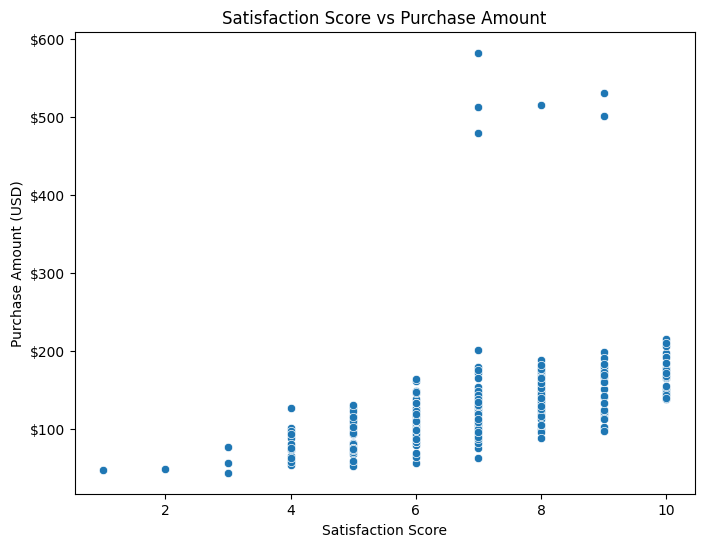

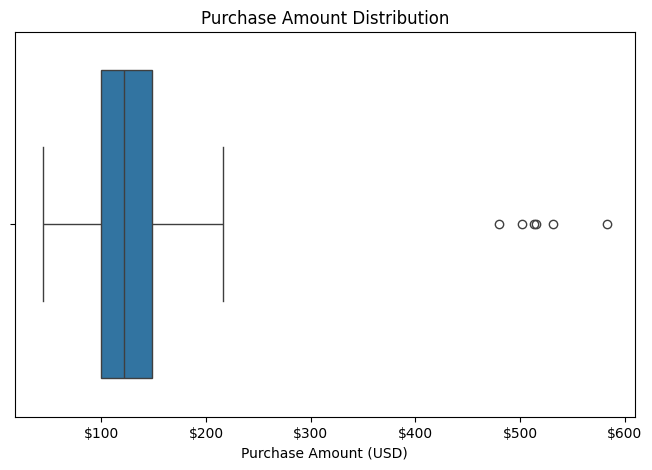

In [23]:
# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Chart 1: Satisfaction score vs. purchase amount (scatter plot)
plt.figure(figsize=(8, 6))
sns.scatterplot(x='satisfaction_score', y='purchase_amount', data=df)
plt.title('Satisfaction Score vs Purchase Amount')
plt.xlabel('Satisfaction Score')
plt.ylabel('Purchase Amount (USD)')
plt.gca().yaxis.set_major_formatter('${x:,.0f}')
plt.show()

# Chart 2: Purchase amount distribution with outliers (boxplot)
plt.figure(figsize=(8, 5))
sns.boxplot(x='purchase_amount', data=df)
plt.title('Purchase Amount Distribution')
plt.xlabel('Purchase Amount (USD)')
plt.gca().xaxis.set_major_formatter('${x:,.0f}')
plt.show()


---
# 💼 Business Insights
*What did I discover?*

- Satisfaction and purchase amount are positively correlated at **0.44**.  
  (만족도와 구매 금액은 **0.44**의 양의 상관관계)
- **6** customers spend **$479.54**–**$582.74**, far above the upper bound of **$222.14**.  
  (고객 **6**명이 **$479.54**~**$582.74**를 써서 상한 **$222.14**를 크게 넘음)
- The mean (**$131.67**) is **$9.55** above the median (**$122.12**) because of those outliers.  
  (그 이상치 때문에 평균 **$131.67**이 중앙값 **$122.12**보다 **$9.55** 높음)  

---
# 🎯 Business Recommendation
*If I were the Business Analyst...*

1. Report the median (**$122.12**) next to the mean when describing a typical customer.  
   (전형적인 고객을 말할 때는 평균과 함께 중앙값 **$122.12**도 보고)
2. Look at the **6** high spenders (**$479.54**–**$582.74**) as a separate group.  
   (고객 **6**명(**$479.54**~**$582.74**)은 별도 집단으로 따로 볼 것)
3. Keep tracking satisfaction, because it moves with purchase amount (**0.44**).  
   (구매 금액과 함께 움직이므로(**0.44**) 만족도를 계속 추적)  

---
# ❌ Mistakes
*What mistakes did I make today?*

- 
- 
- 

---
# ✅ What I Learned
*Today's biggest lesson*

- `np.corrcoef(x, y)[0, 1]` gives the correlation from the 2×2 matrix.  
  (`np.corrcoef(x, y)[0, 1]`로 2×2 행렬에서 상관계수를 꺼냄)
- The IQR method flags values outside Q1 − 1.5×IQR and Q3 + 1.5×IQR, using `np.percentile`.  
  (IQR 방법은 `np.percentile`로 Q1 − 1.5×IQR과 Q3 + 1.5×IQR 밖의 값을 이상치로 봄)
- Outliers pull the mean above the median, and `np.std` uses ddof=0 by default.  
  (이상치는 평균을 중앙값보다 높이고, `np.std`는 기본이 ddof=0)  

---
# 🧠 Reflection

**What was difficult?**  
Why the standard deviation from `np.std` (**67.51**) differs from the `describe()` value (**67.63**).  
(`np.std` 표준편차(**67.51**)가 `describe()` 값(**67.63**)과 다른 이유)

**Why?**  
`np.std` divides by n (ddof=0) and pandas divides by n − 1 (ddof=1).  
(`np.std`는 n으로 나누고(ddof=0) pandas는 n − 1로 나눔(ddof=1))

**How did I solve it?**  
I compared the two numbers and checked the default `ddof` of each function.  
(두 숫자를 비교하고 각 함수의 기본 `ddof`를 확인함)

**What would I do differently next time?**  
Set `ddof` on purpose when I report a sample standard deviation.  
(표본 표준편차를 보고할 때는 `ddof`를 직접 지정하기)

---
# ⭐ Self Evaluation

**Understanding**  
★★★★★★★★☆☆  
The three NumPy results match the charts. The correlation is **0.44** and there are **6** outliers.  
(NumPy 결과 세 개가 차트와 맞음. 상관계수 **0.44**, 이상치 **6**명)  

**Confidence**  
★★★★★★★☆☆☆  

**Difficulty**  
★★★☆☆☆☆☆☆☆  

---
# 📌 Tomorrow
*Tomorrow I will learn:*

- Practice Day 24 — Numpy stats  
  (NumPy로 통계 응용하기)  